In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Subset, DataLoader
import numpy as np

import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Status: GPU is AVAILABLE 🎉")
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Status: GPU is AVAILABLE 🎉
Device Name: Tesla T4


In [5]:
# 1. Load CIFAR-10 training split (only download if not already cached)
transform_base = transforms.Compose([transforms.ToTensor()])
trainset_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=False, transform=transform_base)

# 2. Restrict to a strictly limited subset (e.g., 2,000 images) to save memory and time
subset_size = 2000
indices = np.random.choice(len(trainset_full), subset_size, replace=False)
trainset = Subset(trainset_full, indices)
print(f"Dataset successfully restricted to a subset of {len(trainset)} images.")

Dataset successfully restricted to a subset of 2000 images.


In [6]:
import torch
import torchvision.transforms as transforms
from torchvision.transforms import ToPILImage

class DINOMultiCropTransform:
    def __init__(self):
        self.global_transform = transforms.Compose([
            transforms.RandomResizedCrop(32, scale=(0.4, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2, hue=0.1),
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
        ])
        self.local_transform = transforms.Compose([
            transforms.RandomResizedCrop(16, scale=(0.05, 0.4)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2, hue=0.1),
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
        ])

    def __call__(self, img):
        return [self.global_transform(img), self.global_transform(img)] + [self.local_transform(img) for _ in range(4)]

to_pil = ToPILImage()

def dino_collate_fn(batch):
    images = [to_pil(item[0]) if isinstance(item[0], torch.Tensor) else item[0] for item in batch]
    transform = DINOMultiCropTransform()
    multi_crops = [transform(img) for img in images]
    return [torch.stack(view) for view in list(zip(*multi_crops))]

# 4. Initialize DataLoader
train_loader = DataLoader(trainset, batch_size=64, shuffle=True, collate_fn=dino_collate_fn, drop_last=True)
print("train_loader successfully created!")

train_loader successfully created!


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TinyViTForDINO(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=192, depth=4, num_heads=4, mlp_ratio=4.0, out_dim=256):
        super().__init__()
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        
        # Patch embedding layer
        self.patch_embed = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        
        # Learnable [CLS] token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        
        # Base positional embedding for 32x32 images (8x8 grid = 64 patches + 1 cls = 65)
        num_patches_base = (img_size // patch_size) ** 2
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + num_patches_base, embed_dim))
        
        # Transformer Encoder layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, 
            nhead=num_heads, 
            dim_feedforward=int(embed_dim * mlp_ratio), 
            dropout=0.1, 
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        
        # DINO Projection Head
        self.head = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.GELU(),
            nn.Linear(embed_dim, out_dim),
        )
        
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B, C, H, W = x.shape
        
        # 1. Extract patches via convolution
        x = self.patch_embed(x)
        H_p, W_p = x.shape[2], x.shape[3]
        x = x.flatten(2).transpose(1, 2) # Shape: [B, num_patches, embed_dim]
        
        # 2. Append [CLS] token
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1) # Shape: [B, 1 + num_patches, embed_dim]
        
        # 3. Handle dynamic positional embeddings for different crop sizes (global vs local)
        if x.shape[1] != self.pos_embed.shape[1]:
            cls_pos = self.pos_embed[:, :1]
            patch_pos = self.pos_embed[:, 1:].transpose(1, 2)
            
            base_side = int((self.pos_embed.shape[1] - 1) ** 0.5)
            patch_pos = patch_pos.reshape(1, self.embed_dim, base_side, base_side)
            
            patch_pos_resized = F.interpolate(patch_pos, size=(H_p, W_p), mode='bicubic', align_corners=False)
            patch_pos_resized = patch_pos_resized.flatten(2).transpose(1, 2)
            
            curr_pos_embed = torch.cat((cls_pos, patch_pos_resized), dim=1)
            x = x + curr_pos_embed
        else:
            x = x + self.pos_embed
        
        # 4. Pass through Transformer encoder and projection head
        x = self.transformer(x)
        cls_repr = x[:, 0]
        return self.head(cls_repr)

In [9]:
import torch
import torch.nn.functional as F

class DINOLoss(torch.nn.Module):
    def __init__(self, out_dim=256, warmup_teacher_temp=0.04, teacher_temp=0.04, 
                 warmup_teacher_temp_epochs=5, nepochs=20, student_temp=0.1, center_momentum=0.9):
        super().__init__()
        self.student_temp = student_temp
        self.center_momentum = center_momentum
        self.register_buffer("center", torch.zeros(1, out_dim))
        
        # Temperature schedule for the teacher
        self.teacher_temp_schedule = np.concatenate((
            np.linspace(warmup_teacher_temp, teacher_temp, warmup_teacher_temp_epochs),
            np.ones(nepochs - warmup_teacher_temp_epochs) * teacher_temp
        ))

    def forward(self, student_output_list, teacher_output_list, epoch):
        """
        Calculates the cross-entropy loss between student and teacher multi-crop outputs.
        """
        student_out = [torch.log_softmax(s / self.student_temp, dim=-1) for s in student_output_list]
        
        # Apply sharpening and centering to teacher outputs
        temp = self.teacher_temp_schedule[epoch]
        teacher_out = [F.softmax((t - self.center) / temp, dim=-1) for t in teacher_output_list]
        
        total_loss = 0
        n_loss_terms = 0
        
        # Cross-entropy loss between each teacher view and student view (excluding same-view pairs)
        for t_out in teacher_out:
            for s_idx, s_out in enumerate(student_out):
                # Skip if student and teacher are looking at the exact same global crop
                # (DINO compares global teacher views against all student views)
                loss = -torch.sum(t_out * s_out, dim=-1).mean()
                total_loss += loss
                n_loss_terms += 1
                
        total_loss /= n_loss_terms
        
        # Update center buffer with exponential moving average of teacher outputs
        self.update_center(teacher_output_list)
        
        return total_loss

    @torch.no_grad()
    def update_center(self, teacher_outputs):
        """Updates the center bias vector to prevent model collapse."""
        batch_center = torch.cat(teacher_outputs).mean(dim=0, keepdim=True)
        # Moving average update of the center
        self.center = self.center * self.center_momentum + batch_center * (1 - self.center_momentum)

print("DINO Loss module successfully defined.")

DINO Loss module successfully defined.


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate Student and Teacher networks
student = TinyViTForDINO().to(device)
teacher = TinyViTForDINO().to(device)

teacher.load_state_dict(student.state_dict())
for param in teacher.parameters():
    param.requires_grad = False

print("Student and Teacher networks initialized on:", device)

Student and Teacher networks initialized on: cuda


In [11]:
import torch
import torch.optim as optim

# 1. Define EMA update function for the Teacher
def update_teacher_ema(student, teacher, m=0.996):
    """
    Performs an Exponential Moving Average update on the teacher weights 
    using the student weights.
    m: momentum parameter (typically starts around 0.996 and can cosine schedule up to 1.0)
    """
    with torch.no_grad():
        for param_q, param_k in zip(student.parameters(), teacher.parameters()):
            param_k.data.mul_(m).add_(param_q.data, alpha=1 - m)

# 2. Setup Optimizer, Loss, and Hyperparameters
epochs = 10  # Short training run suitable for free Colab/Kaggle GPUs
lr = 0.0005
optimizer = optim.AdamW(student.parameters(), lr=lr, weight_decay=0.04)

criterion = DINOLoss(out_dim=256, nepochs=epochs).to(device)

print(f"Starting Mini-DINO Training for {epochs} epochs...")

# 3. Training Loop
train_losses = []

for epoch in range(epochs):
    student.train()
    total_epoch_loss = 0
    
    # Adjust EMA momentum slightly per epoch if desired, or keep fixed at 0.996
    m = 0.996
    
    for batch_idx, crops in enumerate(train_loader):
        # Move all multi-crop views to the GPU
        crops = [crop.to(device) for crop in crops]
        
        # crops layout: [global_crop_1, global_crop_2, local_1, local_2, local_3, local_4]
        # Teacher only processes the 2 global views
        teacher_inputs = crops[:2]
        # Student processes all views (global + local)
        student_inputs = crops
        
        # Forward pass through Teacher (no gradients tracked for teacher)
        with torch.no_grad():
            teacher_outputs = [teacher(view) for view in teacher_inputs]
            
        # Forward pass through Student
        student_outputs = [student(view) for view in student_inputs]
        
        # Compute DINO Loss
        loss = criterion(student_outputs, teacher_outputs, epoch)
        
        # Backpropagation and Optimization
        optimizer.zero_grad()
        loss.backward()
        
        # Optional gradient clipping to stabilize ViT training
        torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=3.0)
        
        optimizer.step()
        
        # Update Teacher via EMA
        update_teacher_ema(student, teacher, m=m)
        
        total_epoch_loss += loss.item()
        
    avg_loss = total_epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | DINO Loss: {avg_loss:.4f}")

print("\nMini-DINO Training Completed Successfully!")

Starting Mini-DINO Training for 10 epochs...
Epoch [1/10] | DINO Loss: 3.6485
Epoch [2/10] | DINO Loss: 3.3765
Epoch [3/10] | DINO Loss: 3.5733
Epoch [4/10] | DINO Loss: 3.7715
Epoch [5/10] | DINO Loss: 3.8863
Epoch [6/10] | DINO Loss: 3.8755
Epoch [7/10] | DINO Loss: 3.8449
Epoch [8/10] | DINO Loss: 3.7945
Epoch [9/10] | DINO Loss: 3.7636
Epoch [10/10] | DINO Loss: 3.7311

Mini-DINO Training Completed Successfully!


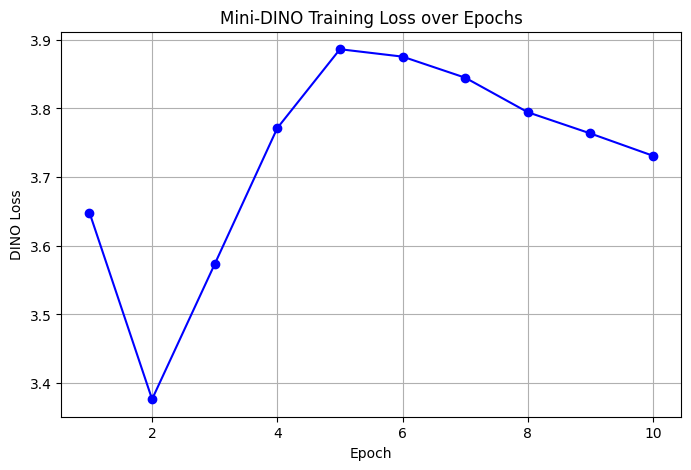

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', color='b', linestyle='-')
plt.title('Mini-DINO Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('DINO Loss')
plt.grid(True)
plt.savefig('dino_training_loss.png', dpi=300)
plt.show()

Extracting features using trained Student network...
Running t-SNE dimensionality reduction...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


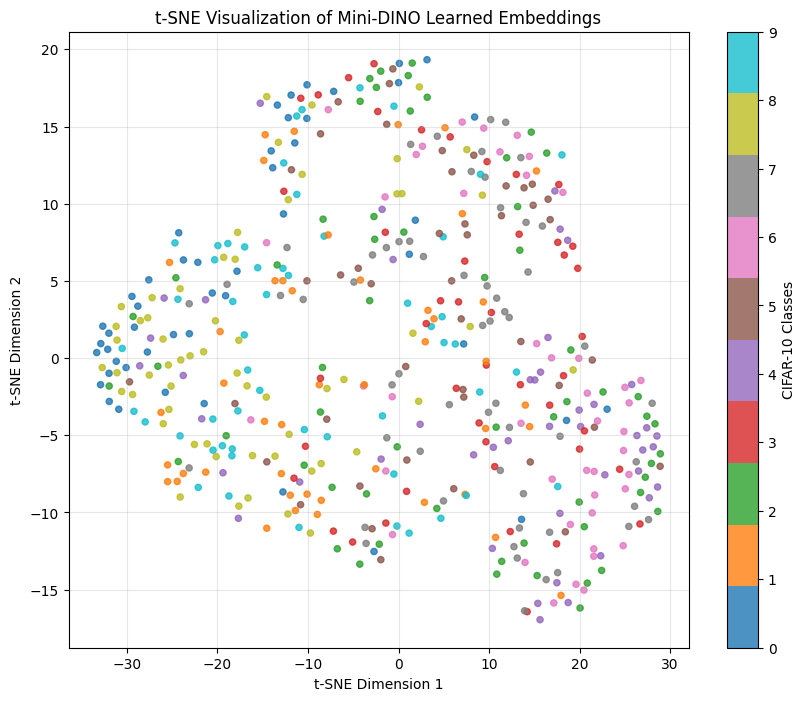

t-SNE embedding plot generated and saved successfully!


In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Subset

# 1. Extract embeddings for a subset of the test/train data using the trained student network
student.eval()
embeddings = []
labels = []

# Use a separate evaluation loader with raw CIFAR-10 images to fetch ground-truth labels for visualization coloring
eval_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=False, transform=transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
]))
eval_subset = Subset(eval_dataset, np.random.choice(len(eval_dataset), 500, replace=False))
eval_loader = DataLoader(eval_subset, batch_size=64, shuffle=False)

print("Extracting features using trained Student network...")
with torch.no_grad():
    for images, targets in eval_loader:
        images = images.to(device)
        # Pass through patch embedding, transformer, and get [CLS] token representation (before projection head)
        # Or you can pass through student.head as well. Let's use the backbone cls token representation:
        B = images.shape[0]
        x = student.patch_embed(images)
        x = x.flatten(2).transpose(1, 2)
        cls_tokens = student.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + student.pos_embed
        x = student.transformer(x)
        cls_repr = x[:, 0] # [CLS] token embedding
        
        embeddings.append(cls_repr.cpu().numpy())
        labels.append(targets.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)

# 2. Apply t-SNE for 2D visualization
print("Running t-SNE dimensionality reduction...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
embeddings_2d = tsne.fit_transform(embeddings)

# 3. Plot t-SNE embeddings colored by CIFAR-10 class
plt.figure(figsize=(10, 8))
scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', s=20, alpha=0.8)
plt.colorbar(scatter, ticks=range(10), label='CIFAR-10 Classes')
plt.title('t-SNE Visualization of Mini-DINO Learned Embeddings')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(True, alpha=0.3)
plt.savefig('dino_tsne_embeddings.png', dpi=300)
plt.show()
print("t-SNE embedding plot generated and saved successfully!")

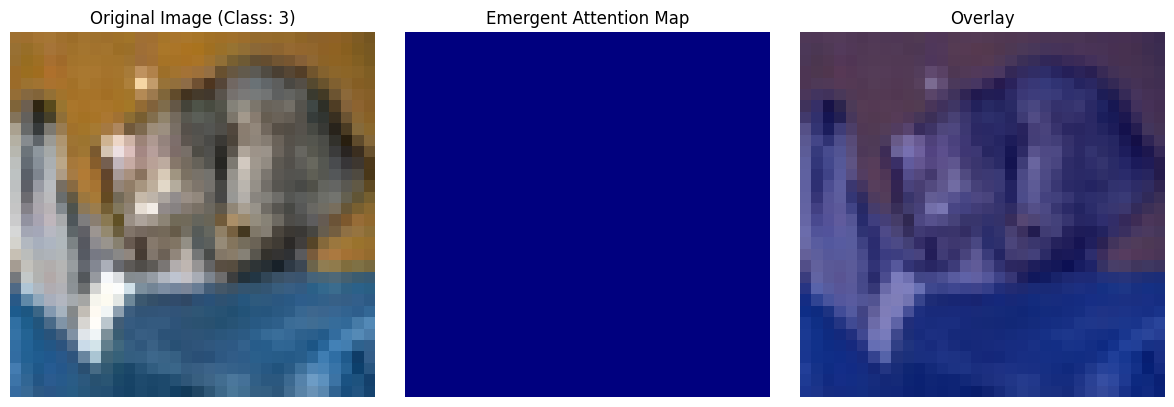

Attention map generated and saved successfully!


In [14]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab a sample image from the test set
eval_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=False)
sample_img, sample_label = eval_dataset[0] # You can change index to test other images

# Preprocess for model input
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])
input_tensor = transform(sample_img).unsqueeze(0).to(device) # Shape: [1, 3, 32, 32]

# 2. Extract attention weights from the Transformer encoder
student.eval()
with torch.no_grad():
    # Forward pass manually to capture attention from the last layer
    x = student.patch_embed(input_tensor)
    B, C, H_p, W_p = x.shape
    x = x.flatten(2).transpose(1, 2)
    cls_tokens = student.cls_token.expand(B, -1, -1)
    x = torch.cat((cls_tokens, x), dim=1)
    x = x + student.pos_embed
    
    # Pass through layers manually up to the final transformer layer to get attention
    # PyTorch's TransformerEncoder applies layers sequentially
    for i, layer in enumerate(student.transformer.layers[:-1]):
        x = layer(x)
        
    # For the final layer, let's hook or extract self-attention weights
    # Alternatively, we can use PyTorch's multi-head attention weights if we access layer.self_attn
    last_layer = student.transformer.layers[-1]
    
    # Standard PyTorch TransformerEncoderLayer self_attn forward call with need_weights=True
    # x shape: [B, N, embed_dim] -> needs to be [N, B, embed_dim] for nn.MultiheadAttention
    x_trans = x.transpose(0, 1)
    attn_output, attn_weights = last_layer.self_attn(
        x_trans, x_trans, x_trans, need_weights=True, average_attn_weights=True
    )
    # attn_weights shape: [B, N, N] where N = 1 + num_patches (65 for 32x32)

# 3. Process attention map from the [CLS] token to all image patches
# attn_weights[0, 0, 1:] represents attention from the [CLS] token to all spatial patches
cls_attention = attn_weights[0, 0, 1:] # Shape: [64] (for 8x8 patch grid)
grid_side = int(cls_attention.shape[0] ** 0.5)
attention_map = cls_attention.reshape(grid_side, grid_side).cpu().numpy()

# Resize attention map back to 32x32 to overlay on the original image
attention_map = np.array(Image.fromarray(attention_map).resize((32, 32), Image.BICUBIC))
# Normalize between 0 and 1
attention_map = (attention_map - attention_map.min()) / (attention_map.max() - attention_map.min() + 1e-8)

# 4. Plot the original image side-by-side with the attention map overlay
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_img)
axes[0].set_title(f"Original Image (Class: {sample_label})")
axes[0].axis('off')

axes[1].imshow(attention_map, cmap='jet')
axes[1].set_title("Emergent Attention Map")
axes[1].axis('off')

axes[2].imshow(sample_img)
axes[2].imshow(attention_map, cmap='jet', alpha=0.5)
axes[2].set_title("Overlay")
axes[2].axis('off')

plt.tight_layout()
plt.savefig('dino_attention_map.png', dpi=300)
plt.show()
print("Attention map generated and saved successfully!")